# Phase 1: does SPR resist representation collapse better than no auxiliary loss?

Trains two agents on the same MinAtar game, same seed, same step budget: the Phase 0 baseline Rainbow agent (no auxiliary loss) and Rainbow + an SPR (Self-Predictive Representations, Schwarzer et al. 2021) head bolted onto the same shared encoder. Both are built from the same `envs/`, `models/`, `agents/` modules as Phase 0 -- SPR only adds `models/spr_head.py` and `agents/sequence_buffer.py` on top.

Tracked for both, side by side: episode return (does the auxiliary loss help or hurt sample efficiency?) and the encoder's effective rank (`diagnostics/effective_rank.py`) over training (does SPR's momentum-encoder self-prediction keep the representation richer than training on the RL loss alone?).

Neither SPR nor iQRL has published numbers on MinAtar (SPR's own published table is on full-size Atari-100k), so "reproducing" it here means confirming the mechanism is implemented correctly and measuring what it actually does on this benchmark, not matching a specific published score.

In [1]:
import os

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    REPO_DIR = "/content/RLresearch"
    if not os.path.exists(REPO_DIR):
        # push local changes before opening this in Colab, or the clone below will be stale
        !git clone https://github.com/Bu3of/RLresearch.git {REPO_DIR}
    %cd {REPO_DIR}
    !pip install -q -r requirements.txt

    CHECKPOINT_DIR = "/content/drive/MyDrive/RLresearch_checkpoints"
else:
    CHECKPOINT_DIR = "./checkpoints"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from envs.minatar_env import MinAtarEnv
from models.encoder import MinAtarEncoder
from models.spr_head import SPRHead
from agents.rainbow_agent import RainbowAgent
from agents.sequence_buffer import SequenceReplayBuffer
from diagnostics.effective_rank import effective_rank, collect_embeddings

In [3]:
GAME = "breakout"
SEED = 0

# SPR runs about 5x slower per step than the baseline on CPU (extra encoder passes for
# augmentation x2 branches, the K-step transition-model unroll, and the projection/prediction
# heads), so this uses a smaller budget than Phase 0's 200k -- still a meaningful
# sample-efficiency comparison, and matches the 100k-step scale the project's README
# already targets for the eventual Atari-100k comparison.
NUM_ENV_STEPS = 100_000
LEARNING_STARTS = 1_000
LOG_EVERY = 2_000
CHECKPOINT_EVERY = 20_000
RANK_EVERY = 10_000       # effective-rank measurement is a 512-step rollout + SVD; not free
RANK_ROLLOUT_STEPS = 512

# SPR hyperparameters (see models/spr_head.py)
SPR_SEQUENCE_LENGTH = 5
SPR_MOMENTUM_TAU = 0.99
SPR_AUG_PAD = 2
SPR_AUX_BATCH_SIZE = 32
SPR_AUX_LOSS_WEIGHT = 1.0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


In [4]:
def train_agent(use_spr, run_name):
    torch.manual_seed(SEED)
    np.random.seed(SEED)

    env = MinAtarEnv(GAME, seed=SEED)
    eval_env = MinAtarEnv(GAME, seed=SEED + 1000)  # separate instance so rank-eval rollouts don't consume training steps
    encoder = MinAtarEncoder(in_channels=env.obs_shape[0])

    if use_spr:
        aux_head = SPRHead(encoder, num_actions=env.num_actions, sequence_length=SPR_SEQUENCE_LENGTH,
                            momentum_tau=SPR_MOMENTUM_TAU, aug_pad=SPR_AUG_PAD)
        seq_buffer = SequenceReplayBuffer(capacity=100_000, obs_shape=env.obs_shape, sequence_length=SPR_SEQUENCE_LENGTH)
    else:
        aux_head, seq_buffer = None, None

    agent = RainbowAgent(
        encoder=encoder, num_actions=env.num_actions, obs_shape=env.obs_shape, device=device,
        aux_head=aux_head, sequence_buffer=seq_buffer,
        aux_batch_size=SPR_AUX_BATCH_SIZE, aux_loss_weight=SPR_AUX_LOSS_WEIGHT,
    )

    checkpoint_path = os.path.join(CHECKPOINT_DIR, f"{run_name}_{GAME}.pt")
    start_step = 0
    episode_returns = []
    rank_history = []  # list of (step, effective_rank)

    if os.path.exists(checkpoint_path):
        ckpt = torch.load(checkpoint_path, map_location=device, weights_only=False)
        agent.load_state_dict(ckpt["agent"])
        start_step = ckpt["step"]
        episode_returns = ckpt.get("episode_returns", [])
        rank_history = ckpt.get("rank_history", [])
        print(f"[{run_name}] resumed from {checkpoint_path} at step {start_step}")
    else:
        print(f"[{run_name}] no checkpoint found, starting from scratch")

    ep_return = 0.0
    obs = env.reset()

    for step in range(start_step, NUM_ENV_STEPS):
        if step < LEARNING_STARTS:
            action = np.random.randint(env.num_actions)
        else:
            action = agent.act(obs)

        next_obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        agent.store_transition(obs, action, reward, next_obs, done)
        ep_return += reward
        obs = next_obs

        if done:
            episode_returns.append(ep_return)
            ep_return = 0.0
            obs = env.reset()

        if step >= LEARNING_STARTS:
            agent.train_step()

        if step % RANK_EVERY == 0 and step > start_step:
            embeddings = collect_embeddings(agent.online_net.encoder, agent, eval_env, n=RANK_ROLLOUT_STEPS)
            rank = effective_rank(embeddings)
            rank_history.append((step, rank))
            print(f"[{run_name}] step={step} effective_rank={rank:.2f} / {encoder.embedding_dim}")

        if step % LOG_EVERY == 0 and episode_returns:
            recent = episode_returns[-20:]
            print(f"[{run_name}] step={step} episodes={len(episode_returns)} mean_return(last20)={np.mean(recent):.2f}")

        if step % CHECKPOINT_EVERY == 0 and step > start_step:
            torch.save({"agent": agent.state_dict(), "step": step,
                        "episode_returns": episode_returns, "rank_history": rank_history}, checkpoint_path)
            print(f"[{run_name}] checkpoint saved at step {step}")

    torch.save({"agent": agent.state_dict(), "step": NUM_ENV_STEPS,
                "episode_returns": episode_returns, "rank_history": rank_history}, checkpoint_path)
    print(f"[{run_name}] training complete, final checkpoint saved")
    return {"episode_returns": episode_returns, "rank_history": rank_history}

In [5]:
baseline_history = train_agent(use_spr=False, run_name="baseline")

[baseline] no checkpoint found, starting from scratch


[baseline] step=2000 episodes=201 mean_return(last20)=0.50


[baseline] step=4000 episodes=367 mean_return(last20)=0.80


[baseline] step=6000 episodes=464 mean_return(last20)=1.75


[baseline] step=8000 episodes=521 mean_return(last20)=2.85


...

[baseline] step=92000 episodes=2147 mean_return(last20)=5.95


[baseline] step=94000 episodes=2177 mean_return(last20)=6.05


[baseline] step=96000 episodes=2205 mean_return(last20)=6.30


[baseline] step=98000 episodes=2233 mean_return(last20)=6.25


[baseline] training complete, final checkpoint saved


In [6]:
spr_history = train_agent(use_spr=True, run_name="spr")

[spr] no checkpoint found, starting from scratch


[spr] step=2000 episodes=225 mean_return(last20)=0.25


[spr] step=4000 episodes=395 mean_return(last20)=1.10


[spr] step=6000 episodes=519 mean_return(last20)=1.50


[spr] step=8000 episodes=617 mean_return(last20)=1.40


...

[spr] step=92000 episodes=2342 mean_return(last20)=5.65


[spr] step=94000 episodes=2374 mean_return(last20)=5.80


[spr] step=96000 episodes=2403 mean_return(last20)=5.95


[spr] step=98000 episodes=2433 mean_return(last20)=5.40


[spr] training complete, final checkpoint saved


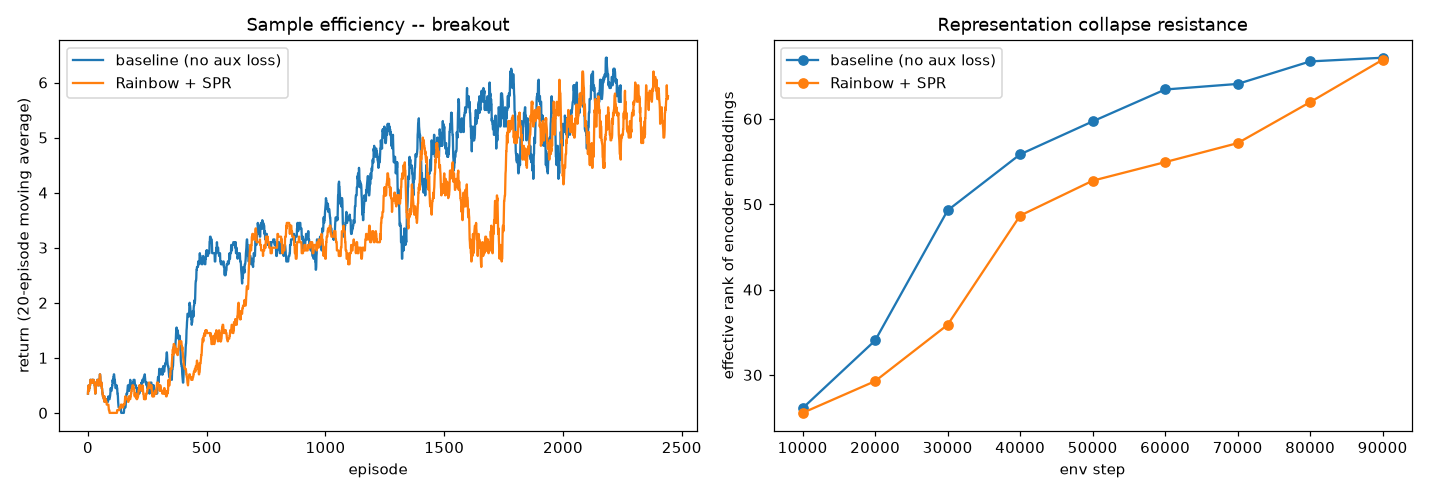

In [7]:
def moving_average(x, window=20):
    if len(x) < window:
        return x
    return np.convolve(x, np.ones(window) / window, mode="valid")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(moving_average(baseline_history["episode_returns"]), label="baseline (no aux loss)")
ax1.plot(moving_average(spr_history["episode_returns"]), label="Rainbow + SPR")
ax1.set_xlabel("episode")
ax1.set_ylabel("return (20-episode moving average)")
ax1.set_title(f"Sample efficiency -- {GAME}")
ax1.legend()

b_steps, b_ranks = zip(*baseline_history["rank_history"]) if baseline_history["rank_history"] else ([], [])
s_steps, s_ranks = zip(*spr_history["rank_history"]) if spr_history["rank_history"] else ([], [])
ax2.plot(b_steps, b_ranks, marker="o", label="baseline (no aux loss)")
ax2.plot(s_steps, s_ranks, marker="o", label="Rainbow + SPR")
ax2.set_xlabel("env step")
ax2.set_ylabel("effective rank of encoder embeddings")
ax2.set_title("Representation collapse resistance")
ax2.legend()

plt.tight_layout()
plt.show()